# Group B scatter plots

Group size: 4,441 students
Students with all 3 summative scores: 4,230
Global max OverallScaleScore: 1816.0
Y-axis ceiling (110%):        1997.6


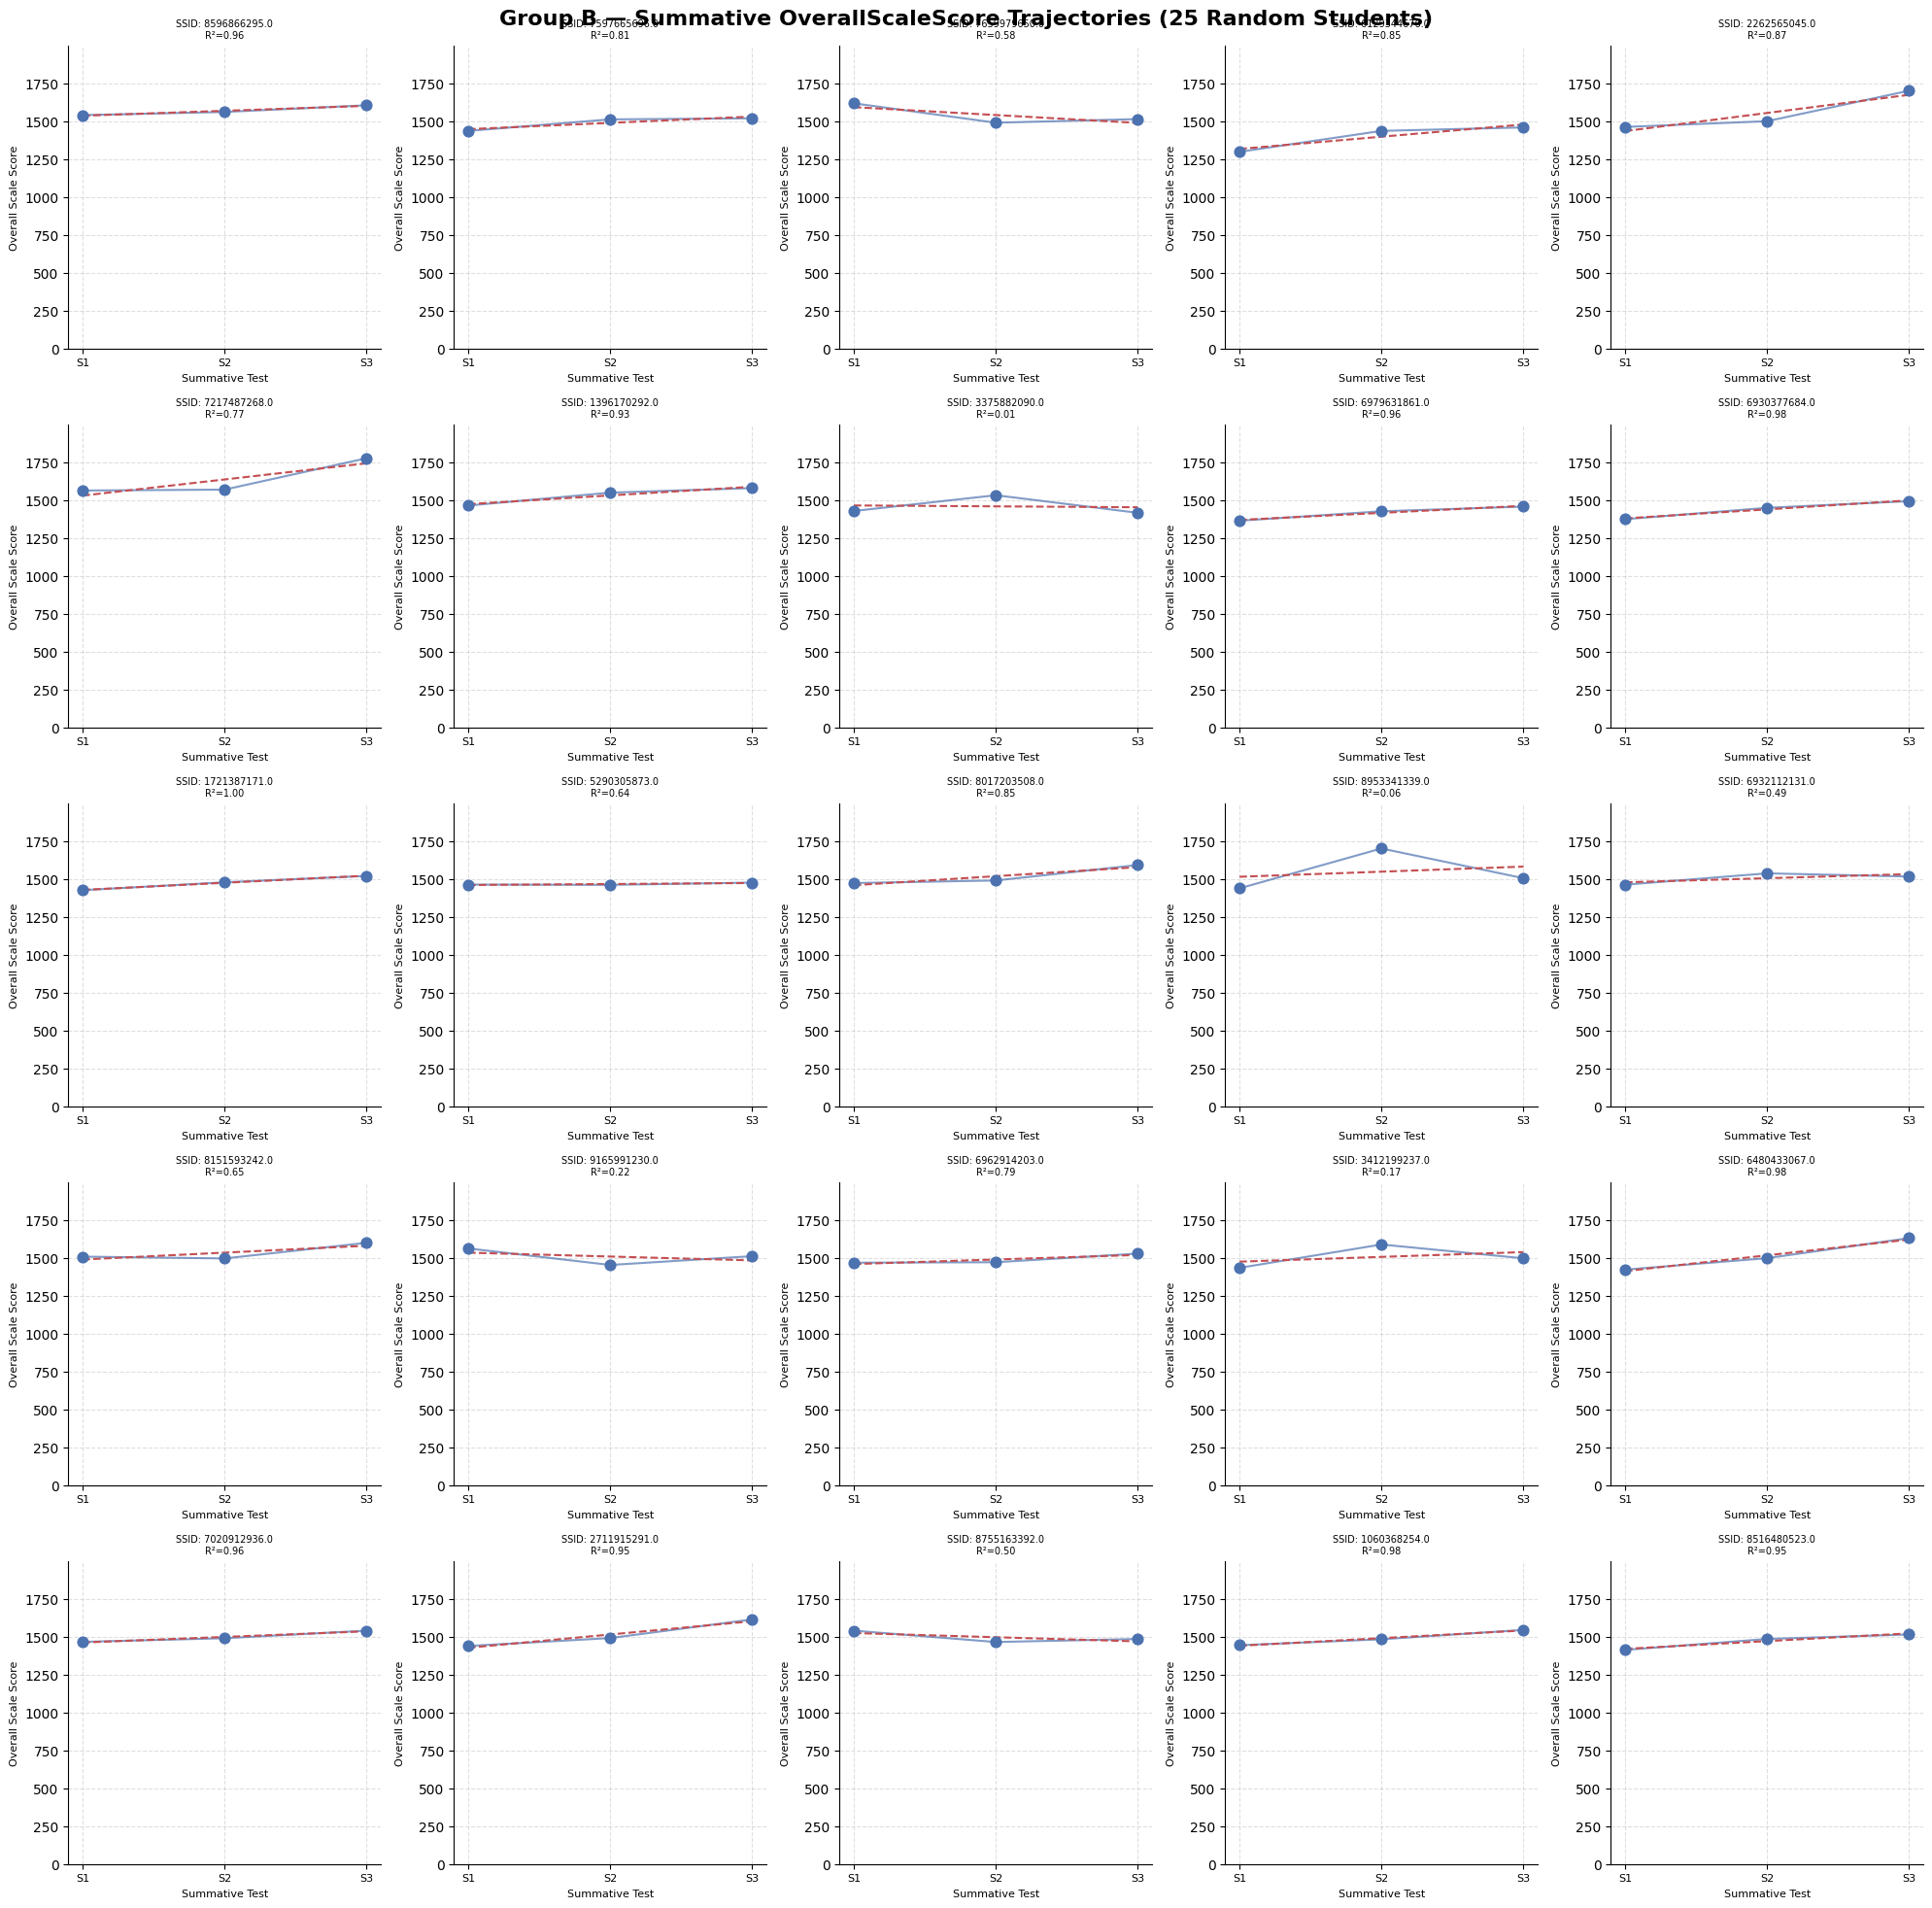

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import os

# --- Paths ---
elpac_dir = "../1095 Data/ELPAC/"
group_csv = "group_b_ssids.csv"  # Change to group_b_ssids.csv for Group B

# --- Load Group SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"Group size: {len(group_ssids):,} students")

# --- Load Summative ELPAC files ---
summative_files = {
    1: "SummativeElpac_22.csv",
    2: "SummativeElpac_23.csv",
    3: "SummativeElpac_24.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    summative_dfs[year_num] = df

# --- Build per-student score list ---
student_scores = {}
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in student_scores:
            student_scores[ssid] = {}
        student_scores[ssid][year_num] = row["OverallScaleScore"]

# --- Keep only students with all 3 scores ---
complete_students = {
    ssid: scores for ssid, scores in student_scores.items()
    if len(scores) == 3
}
print(f"Students with all 3 summative scores: {len(complete_students):,}")

# --- Find global y-axis max across all sampled students ---
all_scores = [
    score
    for scores in complete_students.values()
    for score in scores.values()
]
global_max = max(all_scores)
y_max = global_max * 1.10
print(f"Global max OverallScaleScore: {global_max:.1f}")
print(f"Y-axis ceiling (110%):        {y_max:.1f}")

# --- Randomly select 25 students ---
sampled_ssids = np.random.choice(list(complete_students.keys()), size=25, replace=False)

# --- Plot 5x5 scatter grid ---
fig, axes = plt.subplots(5, 5, figsize=(20, 20))
group_label = os.path.splitext(os.path.basename(group_csv))[0].replace("_ssids", "").replace("_", " ").title()
fig.suptitle(f"{group_label} — Summative OverallScaleScore Trajectories (25 Random Students)",
             fontsize=16, fontweight="bold")

x = np.array([1, 2, 3])

for ax, ssid in zip(axes.flatten(), sampled_ssids):
    y = np.array([complete_students[ssid][1],
                  complete_students[ssid][2],
                  complete_students[ssid][3]])

    # Scatter + connecting line
    ax.scatter(x, y, color="#4C72B0", s=60, zorder=3)
    ax.plot(x, y, color="#4C72B0", linewidth=1.5, alpha=0.7)

    # Trend line + R²
    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_y = slope * x + intercept
    r_squared = r_value ** 2
    ax.plot(x, trend_y, color="#C44E52", linewidth=1.5, linestyle="--", label=f"R²={r_squared:.2f}")

    # Y axis from zero to global max
    ax.set_ylim(0, y_max)

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["S1", "S2", "S3"], fontsize=8)
    ax.set_xlabel("Summative Test", fontsize=8)
    ax.set_ylabel("Overall Scale Score", fontsize=8)
    ax.set_title(f"SSID: {ssid}\nR²={r_squared:.2f}", fontsize=7)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
output_file = f"{group_label.replace(' ', '_')}_trajectories.png"
#plt.savefig(output_file, dpi=150, bbox_inches="tight")
plt.show()
#print(f"Saved: {output_file}")

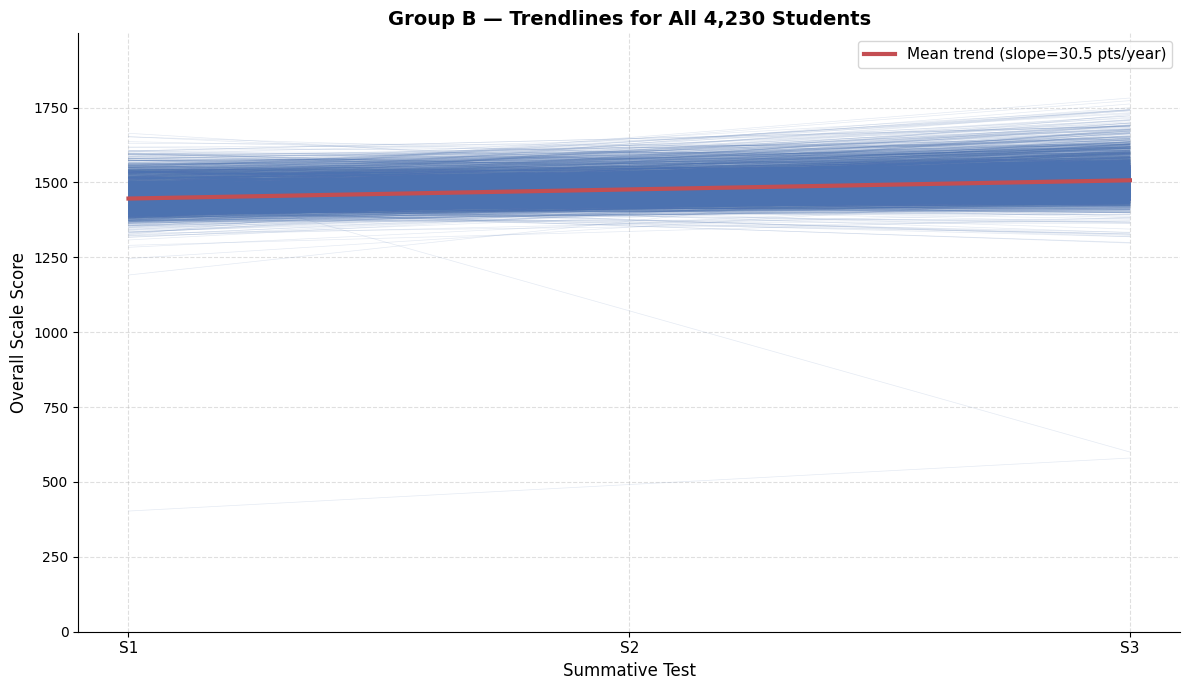

In [2]:
# --- Plot all student trendlines on one figure ---
fig, ax = plt.subplots(figsize=(12, 7))

x = np.array([1, 2, 3])

slopes = []
intercepts = []

for ssid, scores in complete_students.items():
    y = np.array([scores[1], scores[2], scores[3]])
    slope, intercept, _, _, _ = stats.linregress(x, y)
    slopes.append(slope)
    intercepts.append(intercept)
    ax.plot(x, slope * x + intercept, color="#4C72B0", linewidth=0.5, alpha=0.15)

# --- Average trendline ---
mean_slope = np.mean(slopes)
mean_intercept = np.mean(intercepts)
mean_trend_y = mean_slope * x + mean_intercept

ax.plot(x, mean_trend_y, color="#C44E52", linewidth=3, zorder=5,
        label=f"Mean trend (slope={mean_slope:.1f} pts/year)")

ax.set_ylim(0, y_max)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["S1", "S2", "S3"], fontsize=11)
ax.set_xlabel("Summative Test", fontsize=12)
ax.set_ylabel("Overall Scale Score", fontsize=12)
ax.set_title(f"{group_label} — Trendlines for All {len(complete_students):,} Students",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
output_file = f"{group_label.replace(' ', '_')}_all_trendlines.png"
#plt.savefig(output_file, dpi=150, bbox_inches="tight")
plt.show()
#print(f"Saved: {output_file}")

Students with all 3 summative scores and an initial test date: 4,230
Total summative score points to plot: 13,434


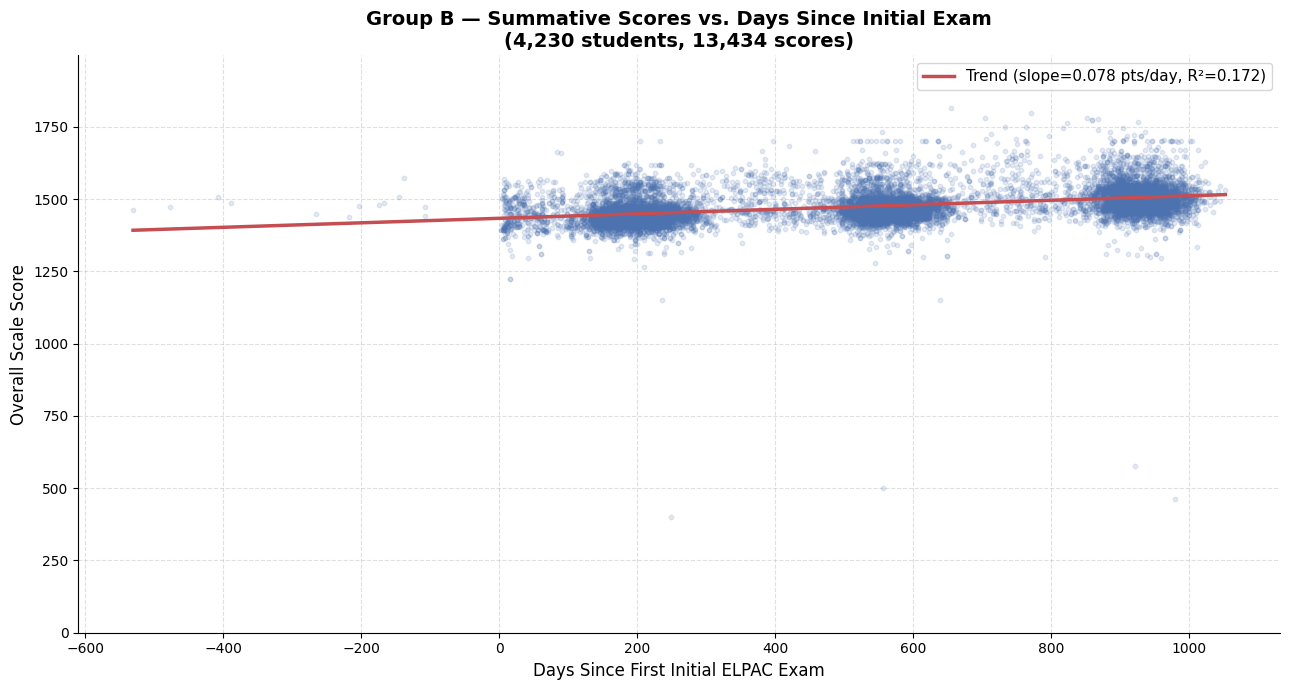

In [3]:
# --- Load Initial ELPAC files to get first test date per student ---
initial_files = {
    "Initial 2022": "InitialElpac_22.csv",
    "Initial 2023": "InitialElpac_23.csv",
    "Initial 2024": "InitialElpac_24.csv",
}

initial_dfs = {}
for label, filename in initial_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    initial_dfs[label] = df

# --- Find each student's earliest initial test date (Group A with 3 summative scores only) ---
first_initial_date = {}
for label, df in initial_dfs.items():
    df_group = df[df["SSID"].isin(complete_students.keys())][["SSID", "TestStartDate"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in first_initial_date or row["TestStartDate"] < first_initial_date[ssid]:
            first_initial_date[ssid] = row["TestStartDate"]

print(f"Students with all 3 summative scores and an initial test date: {len(first_initial_date):,}")

# --- Load summative scores with test dates ---
summative_files = {
    1: "SummativeElpac_22.csv",
    2: "SummativeElpac_23.csv",
    3: "SummativeElpac_24.csv",
}

scatter_x = []
scatter_y = []

for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_dir, filename))
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")

    df_group = df[df["SSID"].isin(complete_students.keys())].dropna(
        subset=["OverallScaleScore", "TestStartDate"]
    )

    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid in first_initial_date:
            days = (row["TestStartDate"] - first_initial_date[ssid]).days
            scatter_x.append(days)
            scatter_y.append(row["OverallScaleScore"])

scatter_x = np.array(scatter_x)
scatter_y = np.array(scatter_y)
print(f"Total summative score points to plot: {len(scatter_x):,}")

# --- Scatter plot ---
fig, ax = plt.subplots(figsize=(13, 7))

ax.scatter(scatter_x, scatter_y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

# Overall trend line + R²
slope, intercept, r_value, _, _ = stats.linregress(scatter_x, scatter_y)
trend_x = np.linspace(scatter_x.min(), scatter_x.max(), 300)
trend_y = slope * trend_x + intercept
r_squared = r_value ** 2
ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
        label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

ax.set_ylim(0, y_max)
ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
ax.set_ylabel("Overall Scale Score", fontsize=12)
ax.set_title(f"{group_label} — Summative Scores vs. Days Since Initial Exam\n"
             f"({len(complete_students):,} students, {len(scatter_x):,} scores)",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
output_file = f"{group_label.replace(' ', '_')}_scatter_days.png"
#plt.savefig(output_file, dpi=150, bbox_inches="tight")
plt.show()
#print(f"Saved: {output_file}")

Points after filtering (x > 0, y > 1000): 13,417


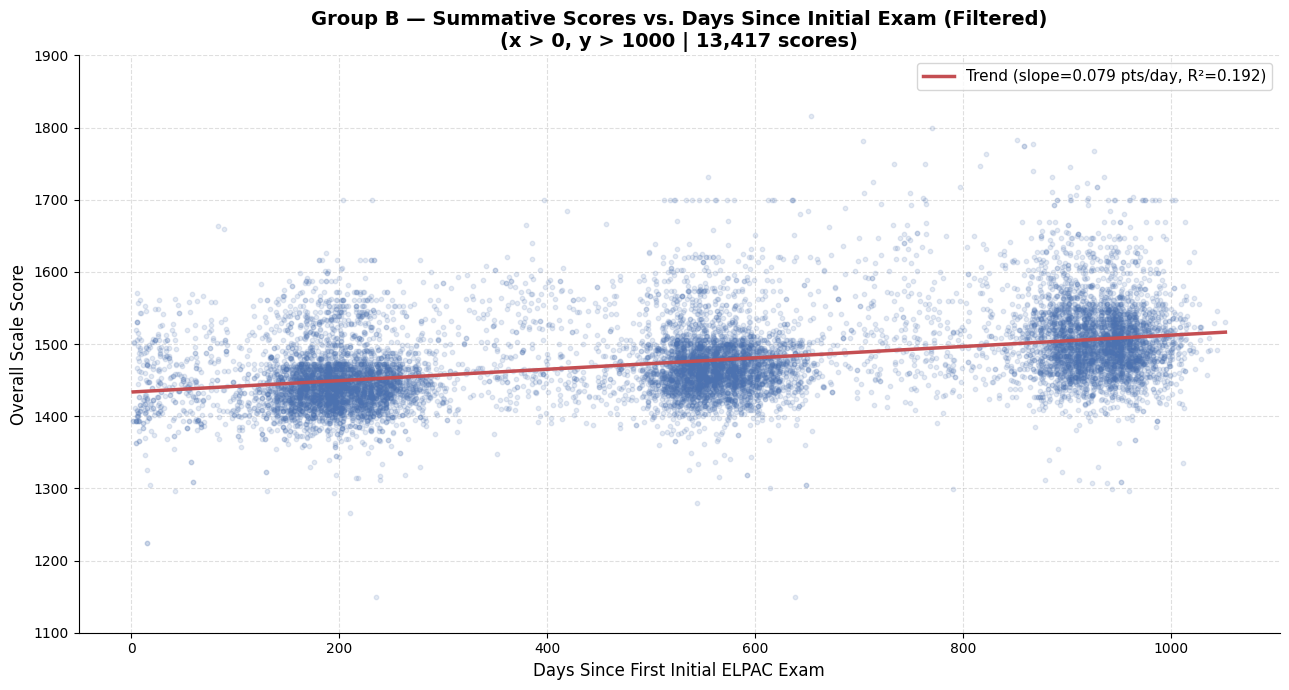

In [4]:
# --- Filter to positive x and y > 1000 ---
mask = (scatter_x > 0) & (scatter_y > 1000)
filtered_x = scatter_x[mask]
filtered_y = scatter_y[mask]
print(f"Points after filtering (x > 0, y > 1000): {len(filtered_x):,}")

# --- Scatter plot ---
fig, ax = plt.subplots(figsize=(13, 7))

ax.scatter(filtered_x, filtered_y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

# Trend line + R²
slope, intercept, r_value, _, _ = stats.linregress(filtered_x, filtered_y)
trend_x = np.linspace(filtered_x.min(), filtered_x.max(), 300)
trend_y = slope * trend_x + intercept
r_squared = r_value ** 2
ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
        label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

ax.set_ylim(1100, 1900)
ax.set_xlabel("Days Since First Initial ELPAC Exam", fontsize=12)
ax.set_ylabel("Overall Scale Score", fontsize=12)
ax.set_title(f"{group_label} — Summative Scores vs. Days Since Initial Exam (Filtered)\n"
             f"(x > 0, y > 1000 | {len(filtered_x):,} scores)",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
output_file = f"{group_label.replace(' ', '_')}_scatter_days_filtered.png"
#plt.savefig(output_file, dpi=150, bbox_inches="tight")
plt.show()
#print(f"Saved: {output_file}")